In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import shutil
import os
import time
import numpy as np
from google.colab import drive
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import classification_report

# CNN

In [ ]:
import tensorflow as tf
import os

# Your image directory path
DATA_DIR = '/content/drive/MyDrive/cnn_data/imgs/train'

# 1. Human-readable label dictionary
class_mapping = {
    0: 'safe_driving',
    1: 'texting_right',
    2: 'talking_right',
    3: 'texting_left',
    4: 'talking_left',
    5: 'operating_radio',
    6: 'drinking',
    7: 'reaching_behind',
    8: 'hair_makeup',
    9: 'talking_passenger'
}

# 2. Load training dataset
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=(224, 224), # Adjust based on your CNN input shape (e.g., 224x224)
    batch_size=32,
    label_mode='int'       # Returns integer labels from 0 to 9
)

# 3. Load validation dataset
val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(224, 224),
    batch_size=32,
    label_mode='int'
)

# Verify the classes discovered by TensorFlow match your folders
print("TensorFlow discovered classes:", train_ds.class_names)


Found 17460 files belonging to 10 classes.
Using 13968 files for training.
Found 17460 files belonging to 10 classes.
Using 3492 files for validation.
TensorFlow discovered classes: ['c0', 'c1', 'c2', 'c3', 'c4', 'c5', 'c6', 'c7', 'c8', 'c9']


In [ ]:
print("Copying dataset from Google Drive to Colab local SSD...")
start_time = time.time()

# Paths (Adjust folder name inside MyDrive if needed)
drive_dataset_path = '/content/drive/MyDrive/cnn_data/imgs/train'
local_dataset_path = '/content/local_driver_dataset'

# If it already exists locally from a previous run, clear it
if os.path.exists(local_dataset_path):
    shutil.rmtree(local_dataset_path)

# Copy the entire folder structure to local SSD for fast I/O performance
shutil.copytree(drive_dataset_path, local_dataset_path)
print(f"Dataset copied successfully in {time.time() - start_time:.2f} seconds!")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Copying dataset from Google Drive to Colab local SSD...
Dataset copied successfully in 265.65 seconds!


In [ ]:
# 2. Data Generators with rescaling and validation split
datagen = ImageDataGenerator(rescale=1./255, validation_split=0.2)

# Training Data (shuffled)
train_data = datagen.flow_from_directory(
    local_dataset_path,
    target_size=(128, 128),
    batch_size=32,
    class_mode='categorical',
    subset='training',
    shuffle=True
)

# Validation Data (CRITICAL: shuffle=False so classification_report matches correctly)
val_data = datagen.flow_from_directory(
    local_dataset_path,
    target_size=(128, 128),
    batch_size=32,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)

# 3. Build CNN Model Architecture for 10 Classes
cnn_model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(128, 128, 3)),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(10, activation='softmax') # Updated to 10 output classes (c0 - c9)
])

cnn_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

cnn_model.summary()

# 4. Crash-Prevention Callbacks
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,               # Stop if validation loss doesn't improve for 5 epochs
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=2,
    min_lr=1e-6
)


Found 13973 images belonging to 10 classes.
Found 3487 images belonging to 10 classes.


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,930 (12.61 MB)

 Trainable params: 3,305,930 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# 5. Train the Model
history = cnn_model.fit(
    train_data,
    validation_data=val_data,
    epochs=30,
    callbacks=[early_stopping, reduce_lr]
)

# 6. Evaluate on Validation Set
loss, accuracy = cnn_model.evaluate(val_data)
print(f"\nValidation Loss: {loss:.4f}")
print(f"Validation Accuracy: {accuracy:.4f}")

# 7. Generate Correct Classification Report
val_data.reset()
y_pred = cnn_model.predict(val_data)
y_pred_classes = np.argmax(y_pred, axis=1)

print("\nClassification Report:")
print(classification_report(
    val_data.classes,
    y_pred_classes,
    target_names=list(val_data.class_indices.keys())
))

Epoch 1/30
437/437 ━━━━━━━━━━━━━━━━━━━━ 54s 101ms/step - accuracy: 0.6676 - loss: 0.9598 - val_accuracy: 0.9630 - val_loss: 0.1391 - learning_rate: 0.0010
Epoch 2/30
437/437 ━━━━━━━━━━━━━━━━━━━━ 32s 72ms/step - accuracy: 0.9247 - loss: 0.2354 - val_accuracy: 0.9845 - val_loss: 0.0573 - learning_rate: 0.0010
Epoch 3/30
437/437 ━━━━━━━━━━━━━━━━━━━━ 30s 69ms/step - accuracy: 0.9556 - loss: 0.1324 - val_accuracy: 0.9894 - val_loss: 0.0413 - learning_rate: 0.0010
Epoch 4/30
437/437 ━━━━━━━━━━━━━━━━━━━━ 29s 67ms/step - accuracy: 0.9689 - loss: 0.0918 - val_accuracy: 0.9914 - val_loss: 0.0316 - learning_rate: 0.0010
Epoch 5/30
437/437 ━━━━━━━━━━━━━━━━━━━━ 32s 74ms/step - accuracy: 0.9752 - loss: 0.0733 - val_accuracy: 0.9920 - val_loss: 0.0334 - learning_rate: 0.0010
Epoch 6/30
437/437 ━━━━━━━━━━━━━━━━━━━━ 30s 69ms/step - accuracy: 0.9790 - loss: 0.0626 - val_accuracy: 0.9946 - val_loss: 0.0281 - learning_rate: 0.0010
Epoch 7/30
437/437 ━━━━━━━━━━━━━━━━━━━━ 44s 102ms/step - accuracy: 0.9816 -

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Get predictions on validation data
val_data.reset()
y_pred = cnn_model.predict(val_data)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = val_data.classes

# Compute confusion matrix
cm = confusion_matrix(y_true, y_pred_classes)
class_labels = list(val_data.class_indices.keys())

# Plot heatmap
plt.figure(figsize=(8, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_labels,
            yticklabels=class_labels)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.title('Confusion Matrix - Driver Behavior Model', fontsize=14)
plt.show()

NameError: name 'val_data' is not defined

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step


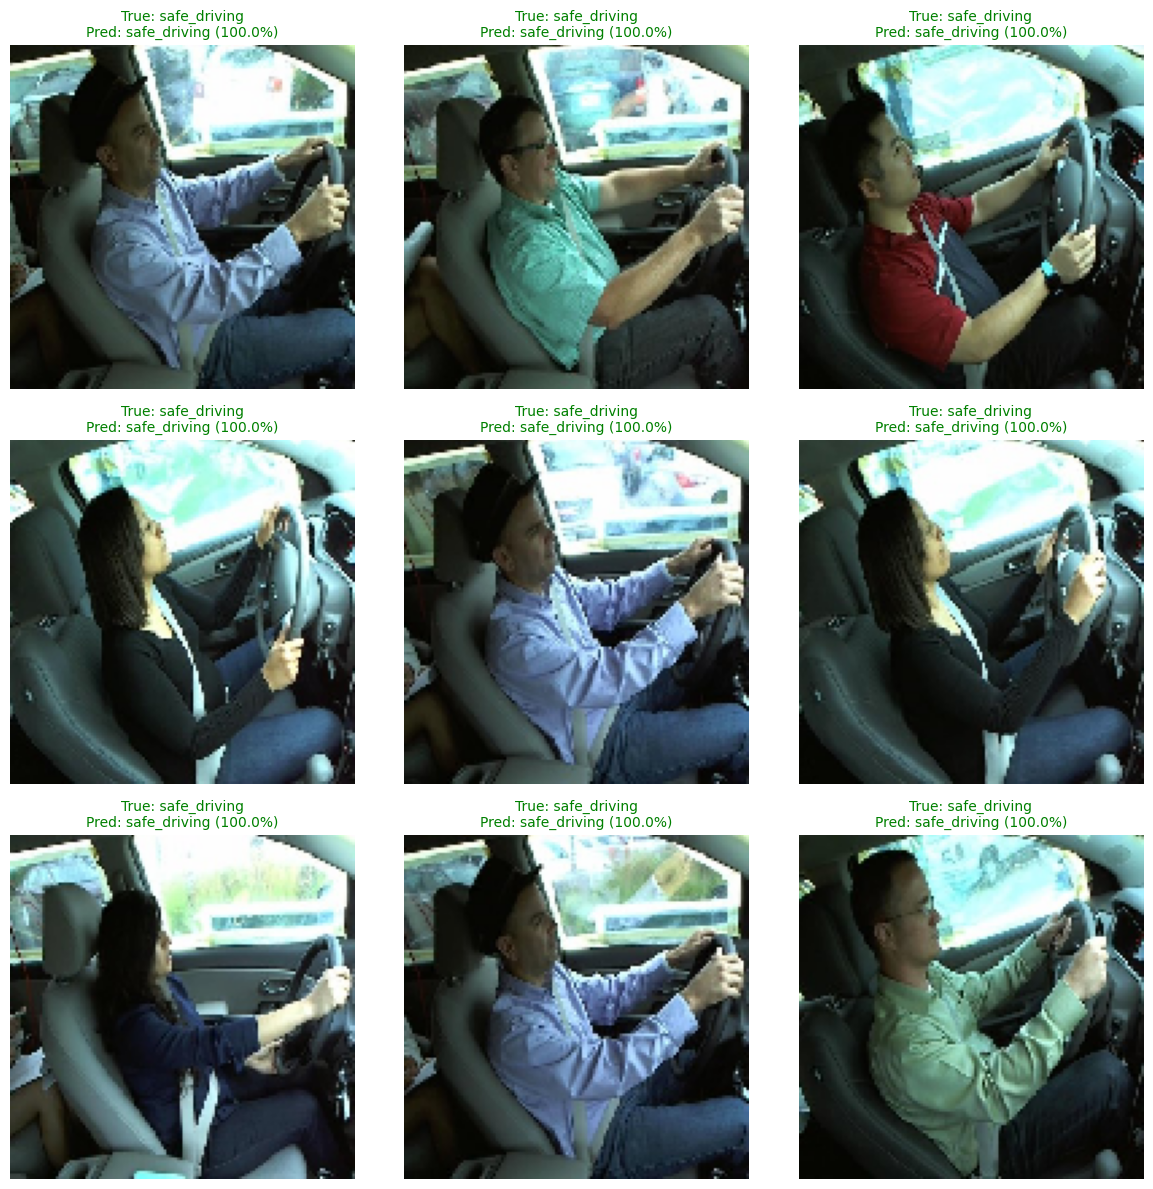

In [ ]:
import matplotlib.pyplot as plt

# Dictionary mapping class indices to human-readable names
class_mapping = {
    0: 'safe_driving', 1: 'Phone_ usage_texting_right', 2: 'Phone_ usage_right',
    3: 'Phone_ usage_texting_left', 4: 'Phone_ usage_left', 5: 'Rash_driving_radio',
    6: 'Rash_driving_drinking', 7: 'Rash_driving_reaching_behind', 8: 'Rash_driving_makeup', 9: 'Rash_driving_talking_to_passenger'
}

# Grab a batch of images and one-hot encoded labels from validation generator
images, labels = next(val_data)
predictions = cnn_model.predict(images)

plt.figure(figsize=(12, 12))
for i in range(9): # Display 9 images
    plt.subplot(3, 3, i + 1)
    plt.imshow(images[i])

    pred_idx = np.argmax(predictions[i])
    true_idx = np.argmax(labels[i])
    confidence = np.max(predictions[i]) * 100

    # Green text if correct, Red text if wrong
    color = 'green' if pred_idx == true_idx else 'red'

    title = f"True: {class_mapping[true_idx]}\nPred: {class_mapping[pred_idx]} ({confidence:.1f}%)"
    plt.title(title, color=color, fontsize=10)
    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
from tensorflow.keras.utils import load_img, img_to_array

def predict_custom_image(image_path):
    # Load and resize the image to match your model's expected input shape (128x128)
    img = load_img(image_path, target_size=(128, 128))
    img_array = img_to_array(img) / 255.0  # Rescale like training data
    img_array = np.expand_dims(img_array, axis=0) # Add batch dimension (1, 128, 128, 3)

    # Predict
    prediction = cnn_model.predict(img_array)
    pred_idx = np.argmax(prediction[0])
    confidence = np.max(prediction[0]) * 100

    print(f"File: {image_path}")
    print(f"Prediction: c{pred_idx} -> {class_mapping[pred_idx]}")
    print(f"Confidence: {confidence:.2f}%\n")

# Example usage (Replace with path to an image in your Drive or local Colab environment):
# predict_custom_image('/content/local_driver_dataset/c1/img_12345.jpg')

In [ ]:
predict_custom_image('/content/drive/MyDrive/cnn_data/imgs/test/img_101737.jpg')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
File: /content/drive/MyDrive/cnn_data/imgs/test/img_101737.jpg
Prediction: c8 -> Rash_driving_makeup
Confidence: 100.00%



# save model

In [ ]:
import os
import joblib
import numpy as np
from tensorflow.keras.models import load_model

# Define your Google Drive directory for models
drive_models_dir = '/content/drive/MyDrive/cnn_data/models'
os.makedirs(drive_models_dir, exist_ok=True)

# 1. Save the Model directly to Google Drive
model_path = os.path.join(drive_models_dir, "driver_behavior_cnn.keras")
cnn_model.save(model_path)

# 2. Capture class order and preprocessing settings
class_indices = train_data.class_indices
cnn_artifact = {
    "class_indices": class_indices,
    "class_names": [k for k, _ in sorted(class_indices.items(), key=lambda kv: kv[1])],
    "img_size": (128, 128),
    "rescale": 1.0 / 255,
    "color_mode": "rgb",
    "confidence_threshold": 0.60,
}
artifact_path = os.path.join(drive_models_dir, "cnn_artifact.pkl")
joblib.dump(cnn_artifact, artifact_path)

print(f"Files successfully saved to Google Drive at: {drive_models_dir}")

Files successfully saved to Google Drive at: /content/drive/MyDrive/cnn_data/models
